# Gesture-Controlled Photo Booth: Baseline YOLO Fine-Tune
**IAT 360 Computer Vision Project, Group 6** (Ben Nichiporik, Daffodil Ho, Joseph Lee, Thu Nguyen)

**Problem.** Taking a photo by hand means reaching for the shutter and getting back into position. We detect hand gestures so the booth can be controlled from where you stand:

| Class | Gesture | Booth action |
|---|---|---|
| 0 | palm (open palm) | start countdown |
| 1 | fist (closed fist) | stop countdown |
| 2 | like (thumbs-up) | accept the photo |
| 3 | dislike (thumbs-down) | retake |

**Task.** Object detection: YOLO finds each hand and classifies the gesture.

This notebook covers step 3 of the brief. It fine-tunes a pretrained YOLO model on our dataset (transfer learning) with **one fixed set of hyperparameters**, the **baseline**. It saves the model and evaluates it on validation data and on test data, including our own photos.

## 1. Dataset

**Sources**
- **HaGRID** (HAnd Gesture Recognition Image Dataset), `palm`, `fist`, `like`, `dislike` classes: images `001`-`368` per class. HaGRID is released under CC BY-SA 4.0. Links: [GitHub](https://github.com/hukenovs/hagrid) · [Hugging Face sample](https://huggingface.co/datasets/cj-mills/hagrid-sample-30k-384p)
- **Our own images**: 8 per class per person, numbered `369`-`400` per class (Amy 369-376, Ben 377-384, Daff 385-392, Joseph 393-400). We annotated them with bounding boxes in MakeSense.ai and exported YOLO-format labels.

The images are not committed to GitHub because the full set is about 1.4 GB. They live in the group's Google Drive folder (`images/` and `labels/`), and `prepare_dataset.py` builds the YOLO folder structure from them.

**Split** (the group's 80/10/10 plan, 320 / 40 / 40 per class). As the brief says, our own images are the test data:
- HaGRID, per class: 320 train / 40 val / 8 test (random, seed 42)
- Our own images: all go to **test** (32 per class, so 40 test per class in total)

**Data issues found and handled**
- Joseph's 32 label files (`*_393`-`*_400`) use a different class order (his MakeSense label list is palm, like, dislike, fist). `prepare_dataset.py` maps them back to our IDs (`0→0, 1→2, 2→3, 3→1`). The sample images below confirm the boxes are labelled correctly.
- Ben's `dislike_380` was the same picture as Amy's `dislike_376`, so it was replaced with a new photo. One duplicate pair is left: `dislike_388` (Daff) = `dislike_393` (Joseph).
- A few labels have mistakes we decided to leave in as human error (loose boxes on `fist_380`, `fist_381`, `fist_384`; unlabelled hands in `fist_376`, `fist_382`, `palm_388`; an unclear gesture in `palm_376`). They are listed, with their effect on the scores, in the baseline report (`report/Baseline_Evaluation_Report.pdf`, Section 8).

Totals: **1280 train / 160 val / 160 test**, 128 of the test images are our own photos.

In [1]:
import json, shutil, subprocess, sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
import ultralytics
from ultralytics import YOLO

from gesture_eval import BASELINE, CLASSES, evaluate, error_analysis

ROOT = Path.cwd()          # run this notebook from the repo root
assert (ROOT / "data.yaml").exists(), "Open the notebook from the repo root"

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
ultralytics.checks()

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Setup complete  (20 CPUs, 31.4 GB RAM, 600.6/930.4 GB disk)


### 1.1 Build the YOLO dataset
`prepare_dataset.py` checks every image/label pair: no orphans, 5 values per row, coordinates in [0, 1], and the class ID matching the file name. It applies Joseph's remap, then copies the files into:
```
dataset/
├── images/{train,val,test}
├── labels/{train,val,test}
├── split_manifest.csv
└── test_team.txt      # only our own photos (team-only test)
```
By default it reads the group Drive folder through Google Drive for desktop (setup in the README). Pass `--images <dir> --labels <dir>` to point it somewhere else.

In [2]:
out = subprocess.run([sys.executable, "prepare_dataset.py"], capture_output=True, text=True)
print(out.stdout, out.stderr)

reading from Google Drive: G:\.shortcut-targets-by-id\1etLHDUerYnEui6lrK9L7-p1An5c1jLfO\ComputerVisionProject-Group6-Dataset
images found: 1600   labels found: 1600   usable pairs: 1600

split      palm     fist     like  dislike    total
train       320      320      320      320     1280
val          40       40       40       40      160
test         40       40       40       40      160

team photos in test: {'Amy': 32, 'Ben': 32, 'Daff': 32, 'Joseph': 32} = 128
Joseph's labels remapped: 32 files
written to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset
 


In [3]:
manifest = pd.read_csv(ROOT / "dataset" / "split_manifest.csv")
summary = pd.crosstab([manifest["split"], manifest["source"]], manifest["class"], margins=True, margins_name="total")
summary[["palm", "fist", "like", "dislike", "total"]]

class         palm  fist  like  dislike  total
split source                                  
test  hagrid     8     8     8        8     32
      team      32    32    32       32    128
train hagrid   320   320   320      320   1280
val   hagrid    40    40    40       40    160
total          400   400   400      400   1600

### 1.2 Sample images with their labels
Top row: Joseph's photos after the class remap. Bottom row: other team photos and HaGRID images.

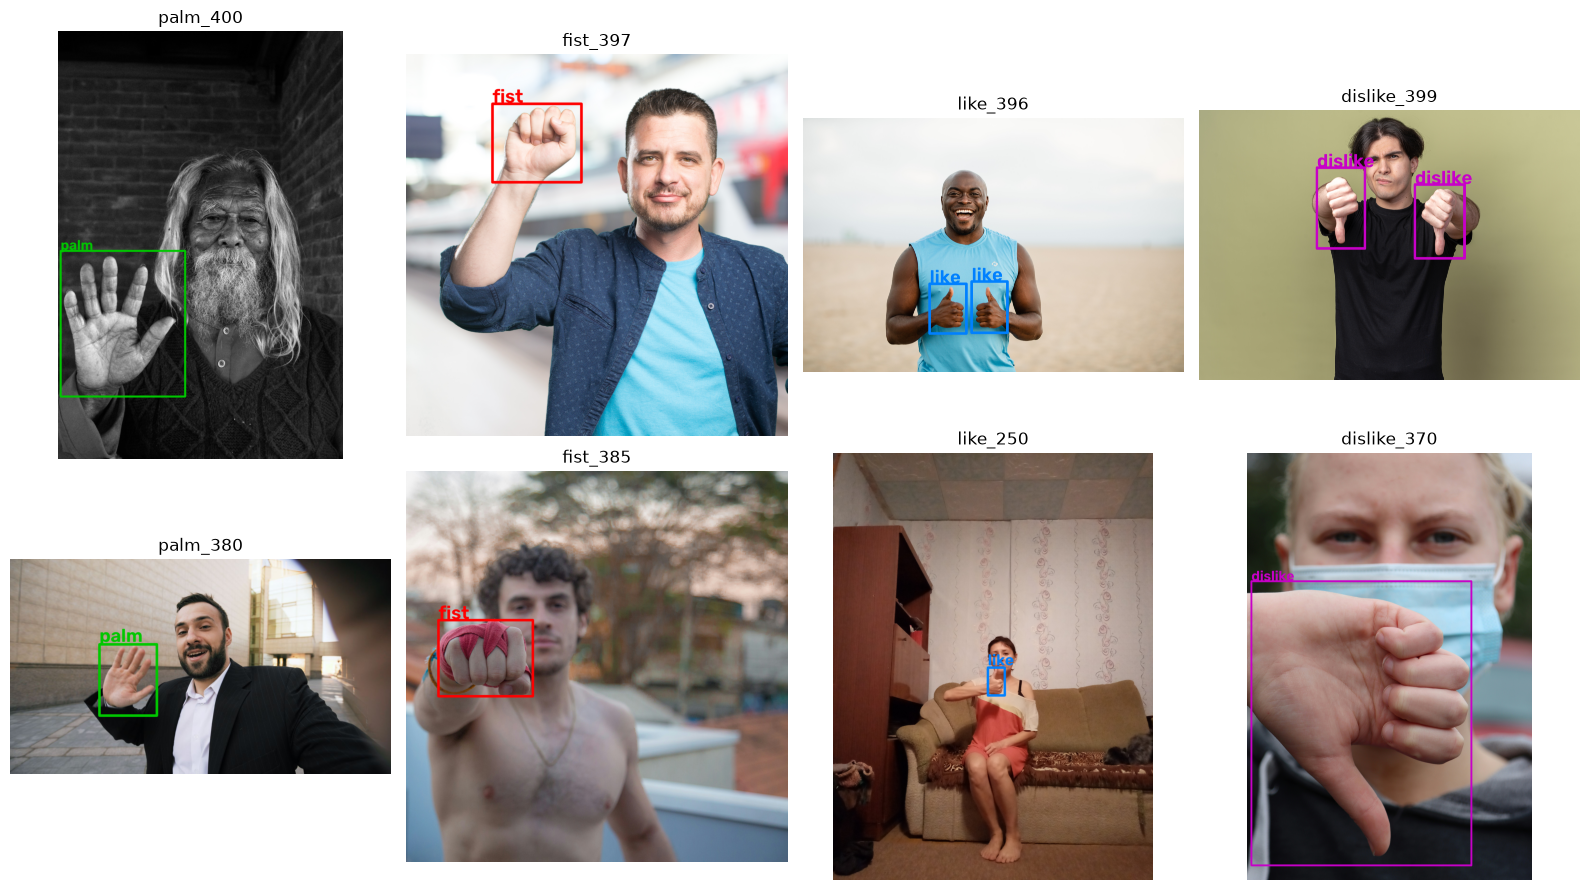

In [4]:
COLORS = [(0, 200, 0), (255, 0, 0), (0, 128, 255), (200, 0, 200)]   # RGB per class

def draw_labels(stem):
    img_path = next((ROOT / "dataset" / "images").rglob(stem + ".*"))
    label_path = ROOT / "dataset" / "labels" / img_path.parent.name / (stem + ".txt")
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in label_path.read_text().splitlines():
        c, x, y, bw, bh = map(float, line.split())
        c = int(c)
        p1 = (int((x - bw / 2) * w), int((y - bh / 2) * h))
        p2 = (int((x + bw / 2) * w), int((y + bh / 2) * h))
        cv2.rectangle(img, p1, p2, COLORS[c], max(3, w // 150))
        cv2.putText(img, CLASSES[c], (p1[0], max(40, p1[1] - 10)), cv2.FONT_HERSHEY_SIMPLEX,
                    w / 600, COLORS[c], max(2, w // 300))
    return img

samples = ["palm_400", "fist_397", "like_396", "dislike_399",
           "palm_380", "fist_385", "like_250", "dislike_370"]
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, stem in zip(axes.flat, samples):
    ax.imshow(draw_labels(stem)); ax.set_title(stem); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Baseline fine-tune (transfer learning)
We start from **YOLOv8s** pretrained on COCO (`yolov8s.pt`, the model from the course notebook) and fine-tune it on our 4 gesture classes. Ultralytics swaps the 80-class COCO head for a 4-class head and trains the whole network.

**Baseline hyperparameters.** They are defined once in `gesture_eval.py` (`BASELINE`), so the tuning notebooks start from exactly the same values. Every value is set explicitly so next week's hyperparameter tuning has a clear reference:
- `optimizer="SGD"` with `lr0=0.01`, `momentum=0.937` and `weight_decay=0.0005`. With the default `optimizer="auto"`, Ultralytics picks its own optimizer and learning rate and ignores `lr0`.
- `epochs=50` with early stopping `patience=15`, `imgsz=640`, `batch=16`
- Augmentation is left at the Ultralytics defaults, except `flipud=0.0` is set on purpose. A vertical flip would turn a *thumbs-up* into a *thumbs-down*, so it would corrupt the labels. A horizontal flip (`fliplr=0.5`) is fine, because left and right hands should both work.
- `seed=0` and `deterministic=True` make the run reproducible.

In [5]:
pd.Series(BASELINE, name="value").to_frame()

,value
data,data.yaml
epochs,50
patience,15
imgsz,640
batch,16
optimizer,SGD
lr0,0.01
momentum,0.937
weight_decay,0.0005
fliplr,0.5


In [6]:
model = YOLO("yolov8s.pt")   # COCO-pretrained weights, downloaded on first use
train_results = model.train(**BASELINE, project=str(ROOT / "runs"), name="baseline", exist_ok=True)
RUN = Path(model.trainer.save_dir)
print("run folder:", RUN)

New https://pypi.org/project/ultralytics/8.4.203 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, 

### 2.1 Training curves

epochs run: 50 | best epoch: 41 (val mAP50 0.990, mAP50-95 0.751)


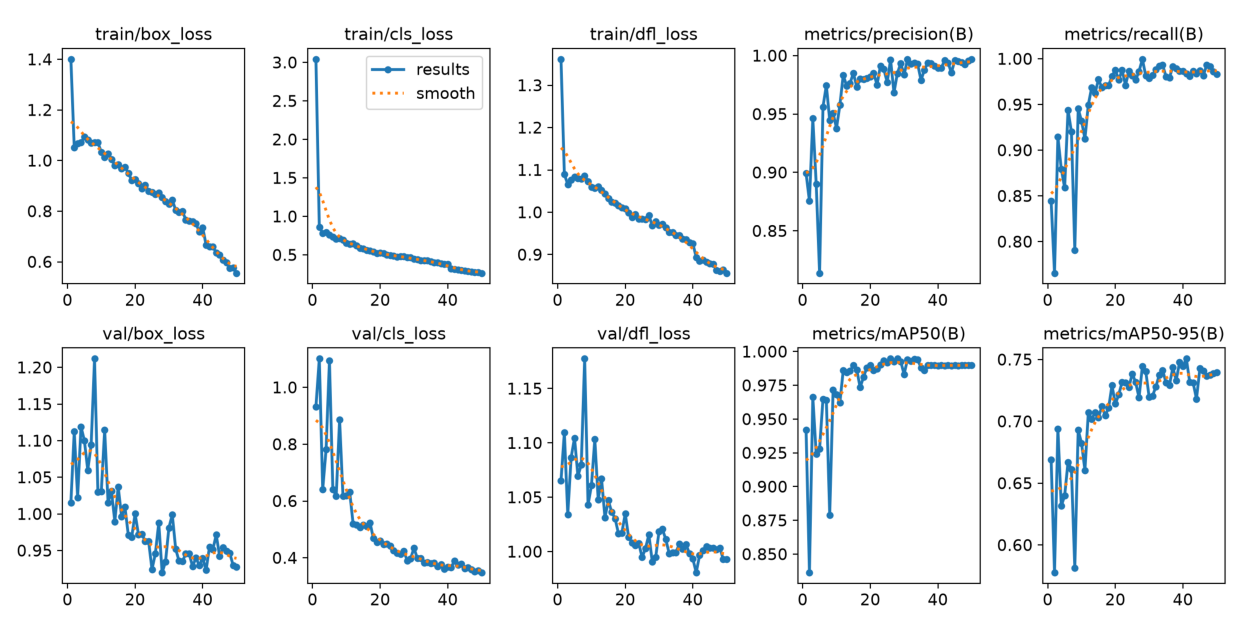

In [7]:
history = pd.read_csv(RUN / "results.csv")
history.columns = history.columns.str.strip()
best_epoch = history.loc[history["metrics/mAP50-95(B)"].idxmax()]
print(f"epochs run: {len(history)} | best epoch: {int(best_epoch['epoch'])} "
      f"(val mAP50 {best_epoch['metrics/mAP50(B)']:.3f}, mAP50-95 {best_epoch['metrics/mAP50-95(B)']:.3f})")

plt.figure(figsize=(16, 8)); plt.imshow(plt.imread(RUN / "results.png")); plt.axis("off"); plt.show()

## 3. Evaluation
We load the best checkpoint (`best.pt`, chosen by validation fitness) and evaluate it with `gesture_eval.evaluate()`, the same code every tuning run uses, on three sets:
1. **Validation**: 160 HaGRID images, the same distribution as training
2. **Test (all)**: 160 images, 32 HaGRID + 128 of our own photos
3. **Test (team only)**: our 128 own photos, the real-world check for the photo booth

Metrics: precision, recall, F1, mAP@0.5, and mAP@0.5:0.95, overall and per class. `error_analysis()` then scores our photos at the deployment threshold (conf 0.25) for the baseline report.

In [8]:
OUT = ROOT / "results" / "baseline"
(ROOT / "models").mkdir(exist_ok=True)
best_pt = ROOT / "models" / "baseline_best.pt"
shutil.copy2(RUN / "weights" / "best.pt", best_pt)
best = YOLO(best_pt)
overall, per_class = evaluate(best_pt, BASELINE["imgsz"], OUT)
ea = error_analysis(best_pt, BASELINE["imgsz"], OUT)
print({k: ea["summary"][k] for k in ["hands", "predictions", "correct", "precision", "recall", "F1"]})

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 903.5±179.6 MB/s, size: 1295.5 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 67.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.2it/s 4.6s.2s1
                   all        160        160       0.99      0.984       0.99      0.748
Speed: 0.8ms preprocess, 4.9ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\baseline_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 param

In [9]:
overall.round(3)

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.990,0.984,0.987,0.990,0.748
"test, all (160)",0.911,0.811,0.858,0.875,0.469
"test, team only (128)",0.894,0.775,0.830,0.845,0.419


In [10]:
per_class.round(3)

precision  recall     F1  mAP50  mAP50-95
                 class                                             
validation       palm         0.996   1.000  0.998  0.995     0.928
                 fist         0.974   1.000  0.987  0.995     0.788
                 like         1.000   0.959  0.979  0.975     0.608
                 dislike      0.988   0.975  0.982  0.995     0.667
                 all          0.990   0.984  0.987  0.990     0.748
test (all)       palm         0.943   0.814  0.874  0.933     0.537
                 fist         0.829   0.682  0.748  0.701     0.256
                 like         0.919   0.903  0.911  0.943     0.527
                 dislike      0.954   0.843  0.895  0.922     0.558
                 all          0.911   0.811  0.858  0.875     0.469
test (team only) palm         0.927   0.765  0.838  0.904     0.452
                 fist         0.758   0.611  0.677  0.625     0.177
                 like         0.927   0.909  0.918  0.948     0.526
                 dislike      0.963   0.814  0.882  0.903     0.519
                 all          0.894   0.775  0.830  0.845     0.419

### 3.1 Confusion matrices (normalized)

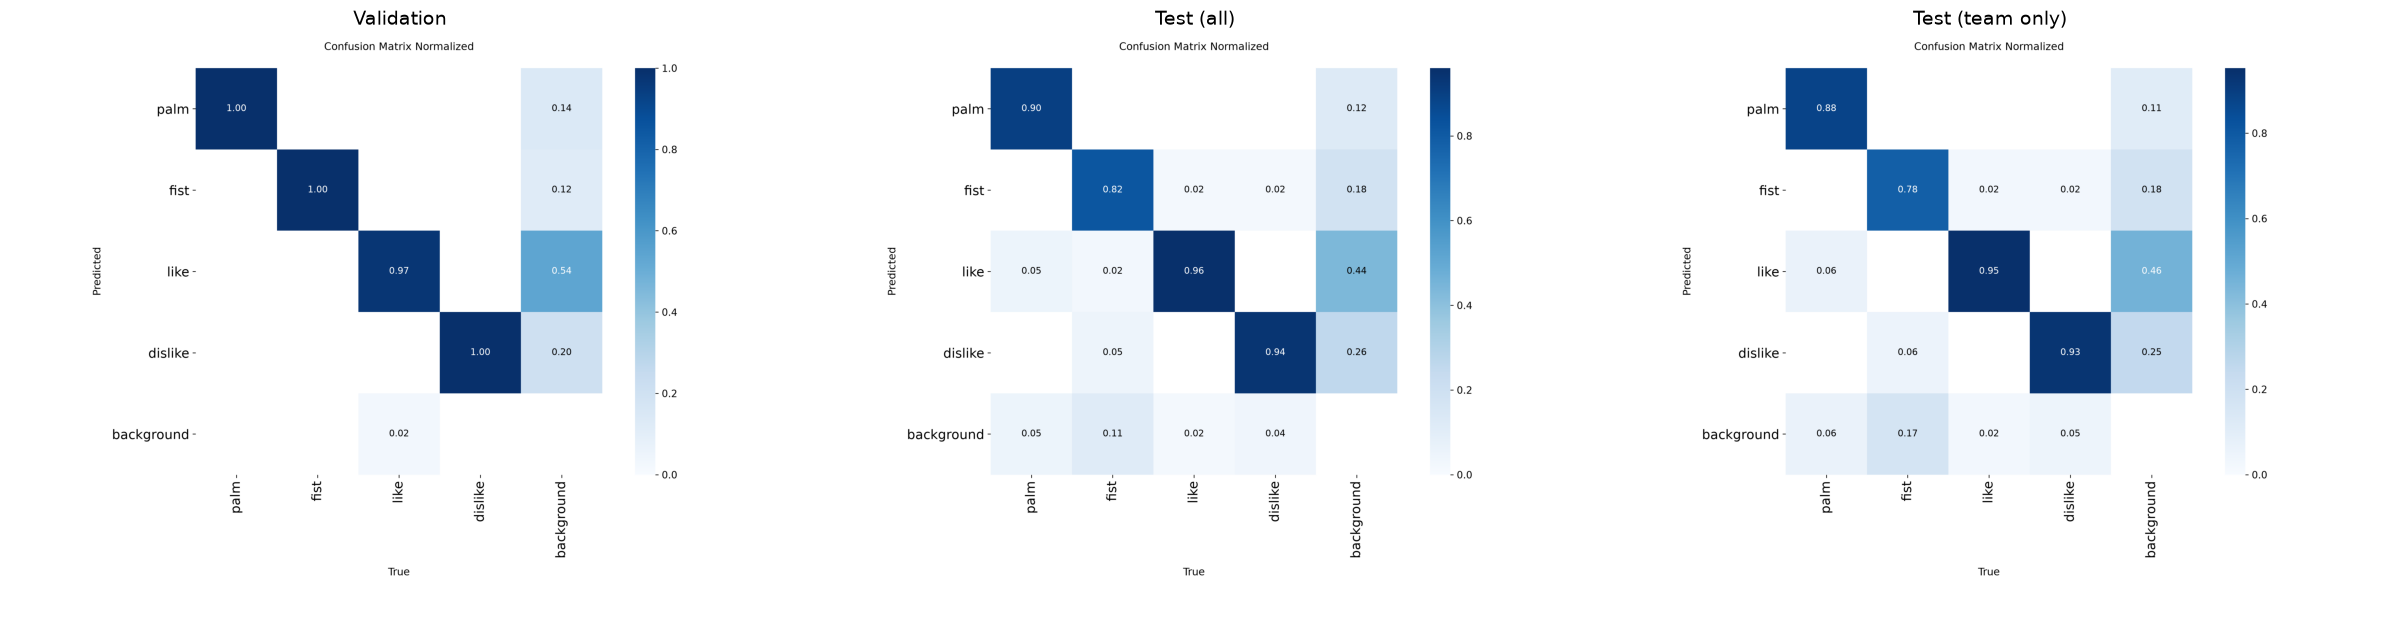

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, (title, prefix) in zip(axes, [("Validation", "val"), ("Test (all)", "test"), ("Test (team only)", "test_team")]):
    ax.imshow(plt.imread(OUT / f"{prefix}_confusion_matrix_normalized.png")); ax.set_title(title, fontsize=14); ax.axis("off")
plt.tight_layout(); plt.show()

### 3.2 Precision-recall curve (team-only test)

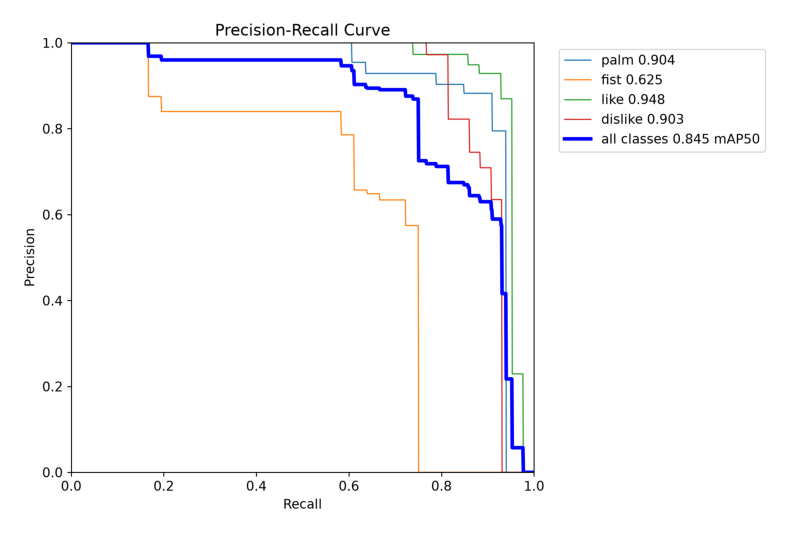

In [12]:
plt.figure(figsize=(10, 7)); plt.imshow(plt.imread(OUT / "test_team_BoxPR_curve.png")); plt.axis("off"); plt.show()

### 3.3 Predictions on our own photos
Two photos per team member (confidence threshold 0.25). Each title gives the ground-truth gesture from the file name.

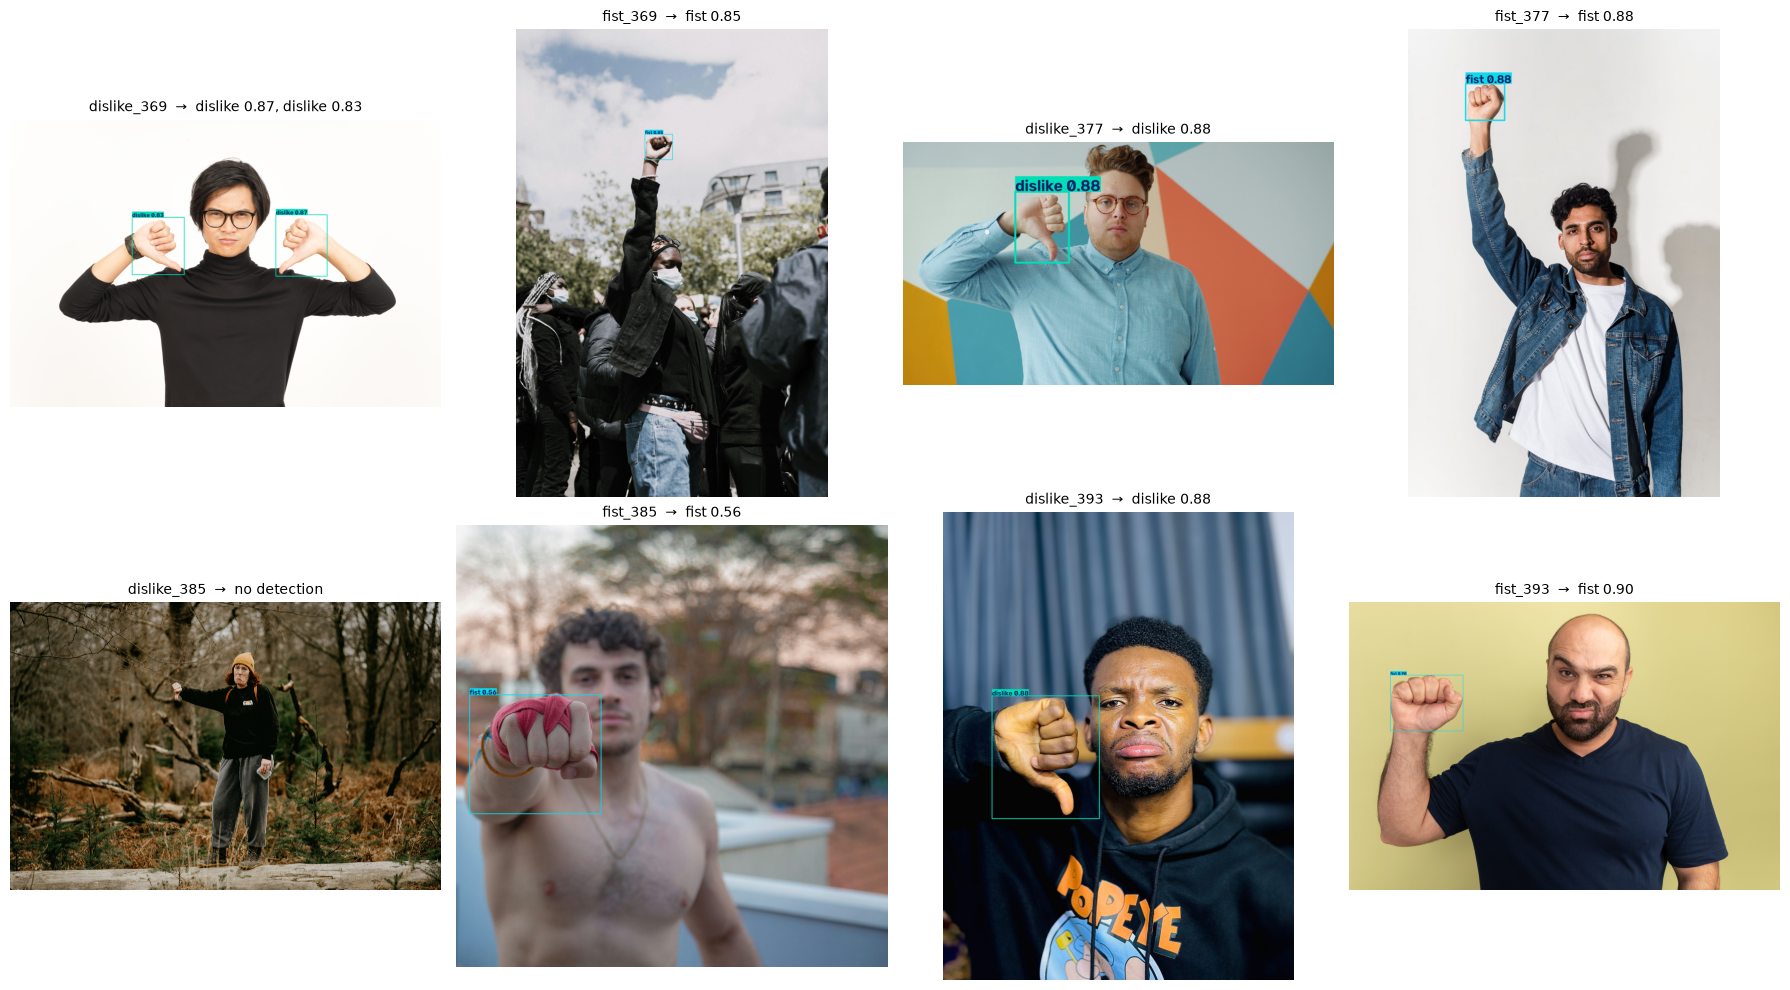

In [13]:
team = manifest[manifest["source"] == "team"].sort_values("file")
picks = team.groupby("person").apply(lambda g: g.drop_duplicates("class").head(2), include_groups=False)
paths = [ROOT / "dataset" / "images" / "test" / f for f in picks["file"]]

preds = best.predict([str(p) for p in paths], imgsz=640, conf=0.25, verbose=False)
pred_fig, axes = plt.subplots(2, 4, figsize=(18, 10))
for ax, p, r in zip(axes.flat, paths, preds):
    ax.imshow(r.plot(line_width=6, font_size=40)[..., ::-1])
    found = ", ".join(f"{CLASSES[int(c)]} {s:.2f}" for c, s in zip(r.boxes.cls, r.boxes.conf)) or "no detection"
    ax.set_title(f"{p.stem}  →  {found}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Save the baseline model and results
- `models/baseline_best.pt`: the fine-tuned baseline weights
- `results/baseline/`: training curves, confusion matrices, PR/F1 curves, `metrics.json`, `per_class.csv` and the error analysis used by the report

In [14]:
for f in ["results.csv", "results.png", "args.yaml", "labels.jpg"]:
    if (RUN / f).exists():
        shutil.copy2(RUN / f, OUT / f)
pred_fig.savefig(OUT / "team_predictions.jpg", dpi=80, bbox_inches="tight")

# evaluate() wrote the metrics; add the training details next to them
metrics = json.loads((OUT / "metrics.json").read_text())
metrics.update({"model": "yolov8s.pt (COCO-pretrained) fine-tuned", "hyperparameters": BASELINE,
                "epochs_run": int(len(history)), "best_epoch": int(best_epoch["epoch"])})
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("saved to", OUT)

saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\results\baseline


## 5. Summary
**Baseline:** YOLOv8s (COCO-pretrained), fine-tuned for 50 epochs with SGD (lr0 0.01, momentum 0.937, weight decay 0.0005), batch 16, imgsz 640 and `flipud=0`. The best checkpoint was epoch 41. Training took about 8.5 minutes on an idle RTX 5060 Ti (15 minutes in a re-run while the GPU was shared; same model, same metrics).

| Set | Images | Precision | Recall | F1 | mAP50 | mAP50-95 |
|---|---|---|---|---|---|---|
| Validation (HaGRID) | 160 | 0.990 | 0.984 | 0.987 | 0.990 | 0.748 |
| Test, all | 160 | 0.911 | 0.811 | 0.858 | 0.875 | 0.469 |
| Test, our photos only | 128 | 0.894 | 0.775 | 0.830 | 0.845 | 0.418 |

**What the results show**
- **Domain gap.** Validation is almost perfect, but on our own photos mAP50 drops by about 0.15. Our photos are more varied than HaGRID's single-person shots (one person facing a phone camera, mostly indoors): wide shots, crowds, outdoor scenes, and the model also had to handle different labelling styles. The test results are the honest estimate for the photo booth.
- **Fist is the weakest class** on our photos (mAP50 0.63, recall 0.61). 12 of 36 fists were missed entirely at conf 0.25, often small, raised fists in wide shots; 3 of those are loose labels rather than model errors. Palm (0.90), like (0.95) and dislike (0.90) transfer well.
- **mAP50-95 is much lower than mAP50** on the test set (0.42 vs 0.85). The model finds the hands, but its boxes don't line up tightly with our MakeSense boxes. Part of this is that each annotator drew boxes differently (some tight around the hand, some including the wrist).
- **Reading the confusion matrix.** Ultralytics builds it from low-confidence predictions, so the "background" row looks large. At the usual 0.25 confidence threshold, the model makes 148 predictions for the 154 hands in our 128 photos, and 124 of those hands are matched with the right class at IoU ≥ 0.5.

The detailed evaluation (error analysis, confidence threshold, hand size, per member) is in `report/Baseline_Evaluation_Report.pdf`, and the `imgsz` tuning is in `Gesture_YOLO_Tuning_imgsz.ipynb`. Compare every tuning run against this baseline on the team-only test set.